# 02-3　雙狹縫：量子力學唯一的謎

**前置**：[00-2 觀看前須知](../00_basics/02_before_quantum.ipynb)、[02-1 波包](01_wavepacket.ipynb)、[02-2 穿隧](02_tunneling.ipynb)

物理學家費曼說，雙狹縫實驗包含了量子力學「**唯一的謎**」，其他的怪事都可以從它推出來。

這一課在**二維平面**上模擬一個粒子穿過一道有兩條縫的牆：

1. 看波函數穿過雙縫、在後面形成**干涉條紋**
2. 比較**只開一條縫**、**兩條都開**、**偷看粒子走哪條縫**三種情況
3. 一顆一顆地打粒子，看條紋怎麼從**隨機的點**慢慢浮現
4. 量條紋間距，和公式 $\lambda L / d$ 比對
5. **在家做**：用雷射筆量頭髮的粗細；用 LED 和三用電表量普朗克常數

## 這一課的新觀念

**二維**：02-1、02-2 的粒子只能沿著一條線（$x$）跑。現在它在平面上，波函數變成 $\psi(x, y)$，
$|\psi(x,y)|^2$ 是在 $(x, y)$ 附近找到粒子的機率密度。數值方法和 02-2 完全一樣（分步法），只是 FFT 換成二維的。

**干涉的關鍵**：兩條縫各自傳出一個波 $\psi_1$、$\psi_2$。量子力學規定：

$$\text{兩條都開：}\quad |\psi_1 + \psi_2|^2 \;=\; |\psi_1|^2 + |\psi_2|^2 + \underbrace{2\,\mathrm{Re}(\psi_1^*\psi_2)}_{\text{干涉項}}$$

**先相加、再平方**。多出來的干涉項可正可負，所以有些地方變亮、有些地方**變成 0**。
如果是古典的子彈，就只會是 $|\psi_1|^2 + |\psi_2|^2$，沒有干涉項。

**吸收邊界**：模擬的區域是有限的，波跑到邊緣時會從另一邊繞回來（FFT 的週期性）。
所以在邊緣放一圈「吸收層」，每一步把那裡的波慢慢減弱，就像實驗室牆上的吸音棉。

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

hbar, m = 1.0, 1.0

# ---- 二維網格 ----
N, L = 512, 200.0
xs = np.linspace(-L / 2, L / 2, N, endpoint=False)
dx = xs[1] - xs[0]
X, Y = np.meshgrid(xs, xs, indexing="ij")          # X[i, j] = xs[i]，Y[i, j] = xs[j]
ks = 2 * np.pi * np.fft.fftfreq(N, d=dx)
KX, KY = np.meshgrid(ks, ks, indexing="ij")

# ---- 實驗設定 ----
k0 = 2.5                       # 入射波數 → 波長 λ = 2π/k0
wavelength = 2 * np.pi / k0
x_wall, wall_thick = -40.0, 4.0
slit_d, slit_w = 8.0, 2.0      # 兩縫中心距離 d、每條縫寬 w
x_screen = 40.0                # 屏幕位置
L_screen = x_screen - x_wall   # 縫到屏幕的距離

# 吸收邊界：離邊緣 15 單位內，每一步乘上一個略小於 1 的數
edge = np.minimum.reduce([X + L / 2, L / 2 - X, Y + L / 2, L / 2 - Y])
absorb = np.where(edge < 15, np.exp(-0.3 * ((15 - edge) / 15) ** 2), 1.0)

print(f"網格 {N}×{N}，格距 {dx:.3f}；波長 λ = {wavelength:.3f}（每個波長約 {wavelength / dx:.0f} 格）")
print(f"縫距 d = {slit_d}，縫寬 w = {slit_w}，縫到屏幕 L = {L_screen}")

網格 512×512，格距 0.391；波長 λ = 2.513（每個波長約 6 格）
縫距 d = 8.0，縫寬 w = 2.0，縫到屏幕 L = 80.0


In [2]:
def wall_potential(open_slits):
    # open_slits: 要打開的縫，例如 ("上", "下")
    in_wall = np.abs(X - x_wall) < wall_thick / 2
    hole = np.zeros_like(X, dtype=bool)
    if "上" in open_slits:
        hole |= np.abs(Y - slit_d / 2) < slit_w / 2
    if "下" in open_slits:
        hole |= np.abs(Y + slit_d / 2) < slit_w / 2
    # 牆高 20，遠高於粒子能量 k0²/2 ≈ 3。牆不能設得太高：分步法每一步在牆內轉 V·dt 的相位，
    # 太大會讓「位能、動能分開算」的誤差變大，牆反而會漏（設 100 時漏掉約 1%，比縫透過的還多）
    return np.where(in_wall & ~hole, 20.0, 0.0)


def initial_packet():
    # x 方向窄、y 方向很寬（接近平面波），往 +x 跑
    sx, sy, x0 = 6.0, 25.0, -75.0
    psi = np.exp(-((X - x0) ** 2) / (4 * sx**2) - Y**2 / (4 * sy**2) + 1j * k0 * X)
    return psi / np.sqrt(np.sum(np.abs(psi) ** 2) * dx * dx)


def run(open_slits, t_end=75.0, dt=0.05, snapshots=()):
    # 回傳：屏幕上累積的強度（沿 y），以及指定時間的快照
    V = wall_potential(open_slits)
    half_V = np.exp(-1j * V * dt / (2 * hbar))
    kinetic = np.exp(-1j * hbar * (KX**2 + KY**2) * dt / (2 * m))
    i_screen = np.argmin(np.abs(xs - x_screen))
    psi = initial_packet()
    screen = np.zeros(N)
    snaps = {}
    for n in range(int(t_end / dt) + 1):
        t = n * dt
        for ts in snapshots:
            if abs(t - ts) < dt / 2:
                snaps[ts] = np.abs(psi) ** 2
        screen += np.abs(psi[i_screen, :]) ** 2 * dt     # 屏幕記錄「累積打到的量」
        psi = half_V * psi
        psi = np.fft.ifft2(kinetic * np.fft.fft2(psi))
        psi = half_V * psi * absorb
    return screen, snaps

## 實驗 1：看波穿過雙縫

模擬耗時 34 秒


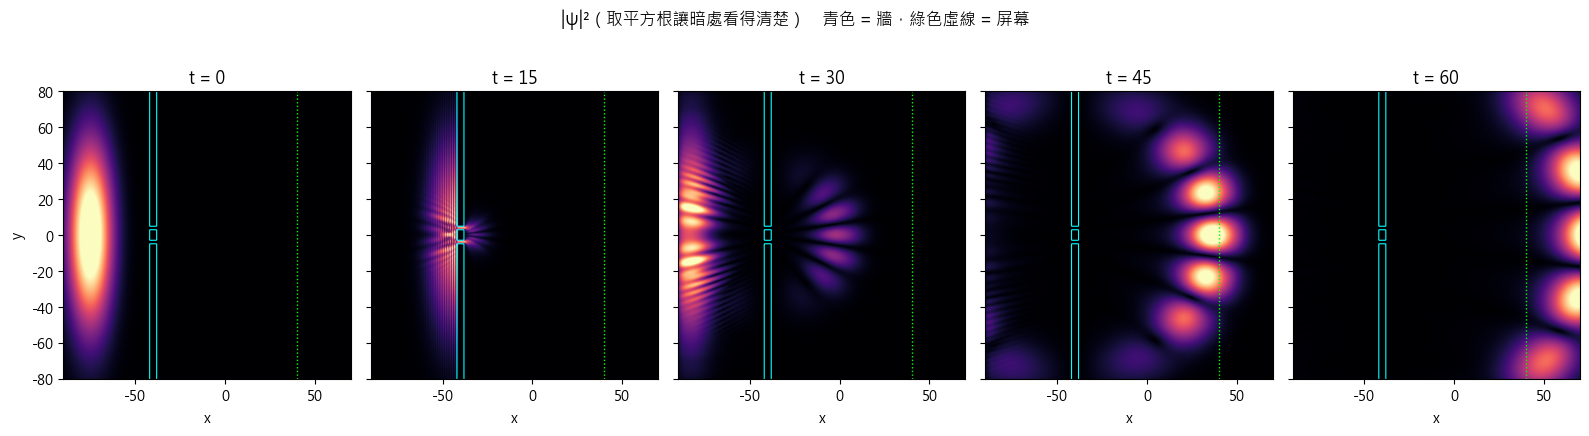

In [3]:
t0 = time.time()
snap_times = [0, 15, 30, 45, 60]
screen_both, snaps = run(("上", "下"), snapshots=snap_times)
print(f"模擬耗時 {time.time() - t0:.0f} 秒")

V_show = wall_potential(("上", "下"))
fig, axes = plt.subplots(1, len(snap_times), figsize=(16, 4), sharey=True)
for ax, t in zip(axes, snap_times):
    img = snaps[t]
    ax.imshow(np.sqrt(img.T), origin="lower", extent=[-L / 2, L / 2, -L / 2, L / 2], cmap="magma",
              vmax=np.sqrt(img.max()) * 0.8)
    ax.contour(xs, xs, V_show.T, levels=[10], colors="cyan", linewidths=0.8)
    ax.axvline(x_screen, color="lime", ls=":", lw=1)
    ax.set_xlim(-90, 70)
    ax.set_ylim(-80, 80)
    ax.set_title(f"t = {t}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
fig.suptitle("|ψ|²（取平方根讓暗處看得清楚）　青色 = 牆，綠色虛線 = 屏幕", y=1.02)
plt.tight_layout()
plt.show()

**觀察**：

- $t = 30$：波打到牆上，大部分被反彈回去，只有兩條縫的位置漏出兩小團。
- $t = 45$ 之後：兩團各自往外擴散成半圓形的波，**重疊的地方出現放射狀的條紋**，這就是干涉。
- 一個粒子的波函數**同時穿過兩條縫**，再自己和自己干涉。

## 實驗 2：一條縫、兩條縫、偷看走哪條縫

三種情況：

1. **只開上面**、**只開下面**：各自得到 $|\psi_1|^2$、$|\psi_2|^2$
2. **兩條都開**：$|\psi_1 + \psi_2|^2$，先相加再平方
3. **偷看粒子走哪條**：在縫旁邊放偵測器。一旦知道粒子走哪條，波函數就只剩那一條的部分，
   結果變成 $|\psi_1|^2 + |\psi_2|^2$，**先平方再相加**，也就是把兩次單縫的結果直接加起來

模擬耗時 72 秒


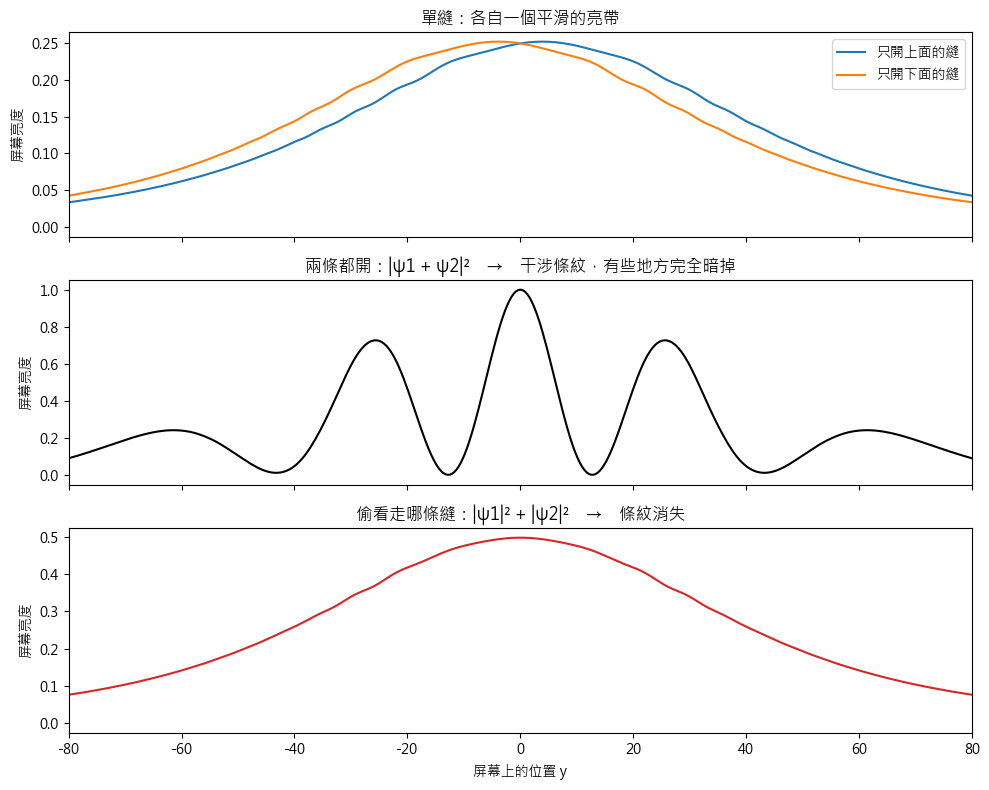

屏幕中央亮度：兩條都開 = 1.00，偷看 = 0.50


In [4]:
t0 = time.time()
screen_top, _ = run(("上",))
screen_bot, _ = run(("下",))
print(f"模擬耗時 {time.time() - t0:.0f} 秒")

screen_which = screen_top + screen_bot               # 偷看：先平方再相加
norm = screen_both.max()

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(xs, screen_top / norm, label="只開上面的縫")
axes[0].plot(xs, screen_bot / norm, label="只開下面的縫")
axes[0].set_title("單縫：各自一個平滑的亮帶")
axes[1].plot(xs, screen_both / norm, "k")
axes[1].set_title("兩條都開：|ψ1 + ψ2|²　→　干涉條紋，有些地方完全暗掉")
axes[2].plot(xs, screen_which / norm, "C3")
axes[2].set_title("偷看走哪條縫：|ψ1|² + |ψ2|²　→　條紋消失")
axes[0].legend(loc="upper right")
for ax in axes:
    ax.set_xlim(-80, 80)
    ax.set_ylabel("屏幕亮度")
axes[-1].set_xlabel("屏幕上的位置 y")
plt.tight_layout()
plt.show()

center = np.argmin(np.abs(xs))
print(f"屏幕中央亮度：兩條都開 = {screen_both[center] / norm:.2f}，偷看 = {screen_which[center] / norm:.2f}")

**觀察**：

- 兩條都開時，中央亮度剛好是「偷看」時的 **2 倍**：兩個波同相，先相加再平方，$|\psi_1+\psi_2|^2 = 4|\psi_1|^2$，而偷看只有 $2|\psi_1|^2$。
- 旁邊**亮暗交替**。暗紋的地方，兩條縫的波剛好互相抵消：**多開一條縫，某些地方反而更暗**。這是古典粒子絕對不可能有的現象。
- 一旦偷看粒子走哪條縫，條紋就**消失**，變成兩個單縫亮帶的總和。
- 偷看本身不必「推」到粒子。只要**資訊存在**，可以分辨走哪條縫，干涉就會消失。這叫**去相干**（decoherence）。

這就是量子力學的**測量問題**：沒人看的時候，粒子像波一樣同時走兩條路；一旦被測量，就只剩一條。
「測量」到底是什麼？為什麼會讓波函數「塌縮」？這個問題到今天都還有爭論。

彭若斯（Roger Penrose）甚至提出：**也許是重力讓疊加態塌縮的**。一個質量處在兩個位置的疊加態，就等於時空本身有兩種彎法，這可能不穩定。
這正好是我們一開始討論的衝突，05 單元會再回來。

## 實驗 3：一顆一顆打粒子

實際的實驗裡，屏幕上不會看到「一片模糊的波」。每個粒子打到屏幕時，都只留下**一個點**。
條紋要等很多粒子打上去之後，才會從點的分佈裡浮現。

1989 年，日立的外村彰（Akira Tonomura）團隊**一次只射一個電子**做出了這個實驗，被讀者票選為「史上最美的物理實驗」之一。
我們用模擬算出的機率分佈 $|\psi|^2$ 來抽樣，重現這個過程：

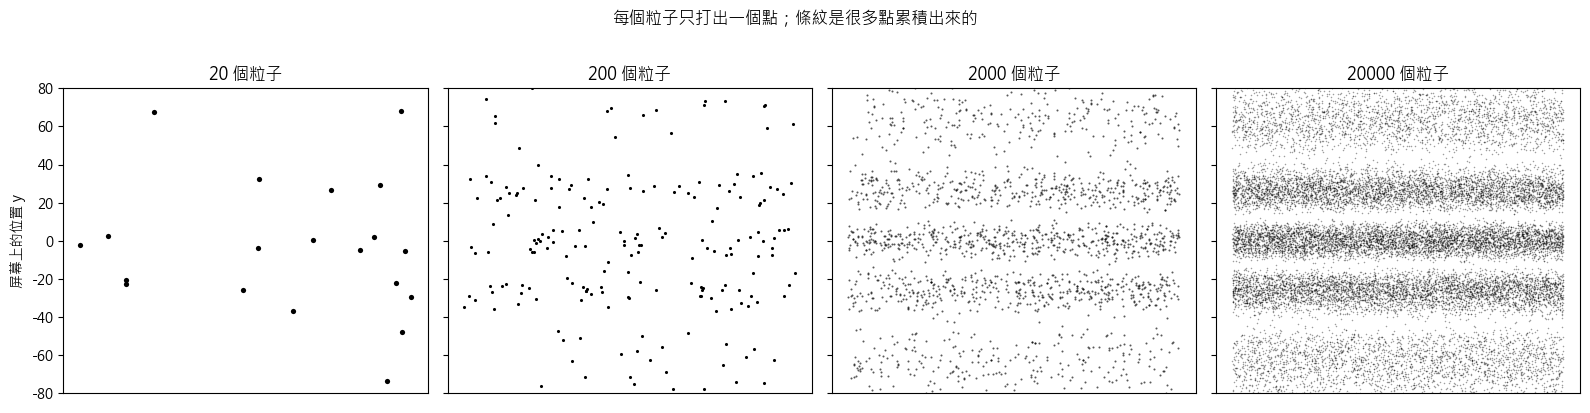

In [5]:
rng = np.random.default_rng(1)
prob = screen_both / screen_both.sum()

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, n in zip(axes, [20, 200, 2000, 20000]):
    hits_y = rng.choice(xs, size=n, p=prob) + rng.uniform(-dx / 2, dx / 2, n)
    hits_z = rng.uniform(0, 1, n)                       # 屏幕的另一個方向，隨機（只是為了畫成 2D）
    ax.scatter(hits_z, hits_y, s=60 / np.sqrt(n) + 0.8, c="k", alpha=min(1, 600 / n + 0.35), lw=0)
    ax.set_ylim(-80, 80)
    ax.set_xticks([])
    ax.set_title(f"{n} 個粒子")
axes[0].set_ylabel("屏幕上的位置 y")
fig.suptitle("每個粒子只打出一個點；條紋是很多點累積出來的", y=1.02)
plt.tight_layout()
plt.show()

**觀察**：20 個粒子時，點看起來完全隨機；2000 個以後，條紋清楚浮現。

**每一個粒子落在哪裡無法預測，但很多粒子的分佈完全可以預測。** 這就是 $|\psi|^2$ 是「機率」的意思（00-2 第 3、4 章）。

## 實驗 4：條紋間距和公式比對

高中光學（楊氏雙狹縫）：屏幕夠遠時，第 $n$ 條亮紋出現在 $d\sin\theta = n\lambda$ 的方向。換成屏幕上的位置：

$$y_n = L\tan\theta_n,\qquad \sin\theta_n = \frac{n\lambda}{d}$$

角度小的時候，相鄰亮紋的間距約為 $\Delta y \approx \lambda L / d$。

在量子力學裡，$\lambda$ 是**德布羅意波長** $2\pi\hbar/p$。同一條公式對光、對電子、對任何粒子都成立。

In [6]:
from scipy.signal import find_peaks

peaks, _ = find_peaks(screen_both / norm, height=0.05, distance=int(5 / dx))
measured = np.sort(xs[peaks])

print(f"波長 λ = {wavelength:.3f}，λL/d = {wavelength * L_screen / slit_d:.2f}\n")
print(f"{'第 n 條':>6}{'公式 y_n':>12}{'模擬':>12}")
for n in range(-2, 3):
    s = n * wavelength / slit_d
    y_formula = L_screen * np.tan(np.arcsin(s))
    y_sim = measured[np.argmin(np.abs(measured - y_formula))]
    print(f"{n:>6}{y_formula:>12.2f}{y_sim:>12.2f}")

波長 λ = 2.513，λL/d = 25.13

 第 n 條      公式 y_n          模擬
    -2      -64.61      -61.33
    -1      -26.47      -25.78
     0        0.00        0.00
     1       26.47       25.78
     2       64.61       61.33


**觀察**：第 ±1 條亮紋和楊氏公式差不到 1（約 3%），第 ±2 條差約 3（約 5%）。
差異來自楊氏公式假設屏幕在**無限遠**，而我們的屏幕只在 80 外，角度越大偏差越明顯。把 `x_screen` 改大（區域也要跟著加大），差異會縮小。

**意義**：一個物質粒子的干涉條紋，用的是 1801 年楊格為**光**寫下的同一條公式。
光是波也是粒子（光子），電子是粒子也是波，這叫**波粒二象性**。

## 在家做實驗 1：用雷射筆量頭髮有多粗

**材料**：紅色雷射筆（包裝上通常標波長，約 650 nm）、一根頭髮、膠帶、一面白牆、捲尺。

**做法**：

1. 把頭髮橫向繃緊，用膠帶貼在一個框（例如紙板挖洞）上
2. 雷射筆照向頭髮，讓光打到幾公尺外的白牆
3. 牆上會出現一排**亮暗相間的光點**（頭髮擋住光的效果和單縫一樣，叫 Babinet 原理）
4. 量出牆和頭髮的距離 $L$，以及**相鄰兩個暗點**的間距 $\Delta y$（量 10 個間距再除以 10 比較準）

**計算**：$\text{頭髮粗細 } d = \dfrac{\lambda L}{\Delta y}$

> ⚠️ **安全**：絕對不要讓雷射直接或經過反射照進眼睛。

下面的數字是**示意用**，請換成你自己量到的：

In [7]:
# ===== 換成你自己的測量 =====
laser_wavelength_nm = 650      # 雷射筆波長（看包裝）
L_m = 3.00                     # 頭髮到牆的距離（公尺）
ten_gaps_cm = 27.0             # 10 個暗點間距加起來（公分）← 示意數字
# ===========================

dy = ten_gaps_cm / 100 / 10
d = laser_wavelength_nm * 1e-9 * L_m / dy
print(f"相鄰暗點間距 Δy = {dy * 1000:.1f} mm")
print(f"頭髮粗細 d = λL/Δy = {d * 1e6:.0f} 微米（一般頭髮約 50–100 微米）")

相鄰暗點間距 Δy = 27.0 mm
頭髮粗細 d = λL/Δy = 72 微米（一般頭髮約 50–100 微米）


## 在家做實驗 2：用 LED 量普朗克常數 $h$

**原理**：LED 發光時，每個電子放出一個光子。電子通過 LED 獲得的能量是 $eV$，光子的能量是 $hc/\lambda$。
LED 剛好開始發光時，兩者大約相等：

$$eV_{\text{起亮}} \approx \frac{hc}{\lambda}\quad\Rightarrow\quad V_{\text{起亮}} \approx \frac{hc}{e}\cdot\frac{1}{\lambda}$$

把幾顆不同顏色 LED 的 $V_{\text{起亮}}$ 對 $1/\lambda$ 畫圖，**斜率就是 $hc/e$**，從中可以算出 $h$。

**材料**：紅、橙、黃、綠、藍色 LED 各一顆（電子材料行有賣，查規格表的波長）、可調電源或電池加可變電阻、1 kΩ 電阻（**一定要串聯，保護 LED**）、三用電表。

**做法**：從 0 慢慢調高電壓，在暗處看 LED **剛開始微微發光**的那一刻，記下 LED 兩端的電壓。

下面的數字是**常見 LED 的典型值，只供示意**，請換成你自己量到的：

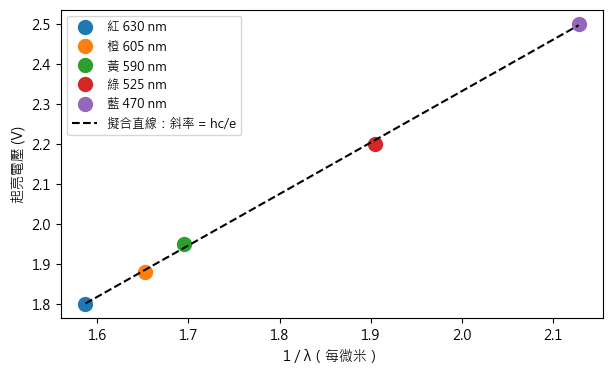

量到的 h = 6.88e-34 J·s
標準值 h = 6.626e-34 J·s，相差 +4%


In [8]:
# ===== 換成你自己的測量 =====
leds = [  # (顏色, 波長 nm, 起亮電壓 V) ← 示意數字
    ("紅", 630, 1.80),
    ("橙", 605, 1.88),
    ("黃", 590, 1.95),
    ("綠", 525, 2.20),
    ("藍", 470, 2.50),
]
# ===========================

e, c = 1.602e-19, 2.998e8
inv_lambda = np.array([1 / (lam * 1e-9) for _, lam, _ in leds])
V_on = np.array([v for _, _, v in leds])
slope, intercept = np.polyfit(inv_lambda, V_on, 1)
h_measured = slope * e / c

fig, ax = plt.subplots(figsize=(7, 4))
for (name, lam, v), il in zip(leds, inv_lambda):
    ax.plot(il / 1e6, v, "o", ms=10, label=f"{name} {lam} nm")
fit_x = np.linspace(inv_lambda.min(), inv_lambda.max(), 10)
ax.plot(fit_x / 1e6, slope * fit_x + intercept, "k--", label=f"擬合直線：斜率 = hc/e")
ax.set_xlabel("1 / λ（每微米）")
ax.set_ylabel("起亮電壓 (V)")
ax.legend(fontsize=9)
plt.show()

print(f"量到的 h = {h_measured:.2e} J·s")
print(f"標準值 h = 6.626e-34 J·s，相差 {h_measured / 6.626e-34 - 1:+.0%}")

用 LED 量 $h$，誤差在 10–30% 以內就算很成功了。
誤差的來源有：「剛開始亮」很難判斷、不同顏色的 LED 材料不同、LED 發的光不是單一波長。

但這個實驗的意義很大：**你用桌上的零件，量到了一個 $10^{-34}$ 等級的常數**，而它決定了整個量子世界的尺度。

## 總結

| 實驗 | 結果 | 意義 |
|---|---|---|
| 波穿過雙縫 | 一個粒子的波同時穿過兩條縫，自己和自己干涉 | 疊加 |
| 單縫 / 雙縫 / 偷看 | 多開一條縫反而有地方更暗；偷看就沒有條紋 | 測量問題、去相干 |
| 一顆一顆打 | 單一個點不可預測，分佈可以預測 | 機率詮釋 |
| 條紋間距 | 和楊氏公式吻合 | 波粒二象性 |
| 在家實驗 | 量頭髮粗細、量 $h$ | 量子尺度可以親手碰到 |

**02 量子單元到這裡結束。** 量子力學的核心：**疊加、干涉、機率、不確定性、穿隧**，全部都有一個共同點：
它們只在 $\hbar \ne 0$ 時存在，而且都發生在一個**固定不變的時空舞台**上（02-1 的那個 $t$）。
接下來的 03、04 單元，就是要把這個舞台拆掉。

## 練習

1. 把 `slit_d` 改成 16（兩縫距離加倍），條紋間距會怎麼變？和 $\lambda L/d$ 比對。
2. 把 `k0` 改成 3.5（粒子動量更大，波長更短），條紋怎麼變？（提示：$\lambda = 2\pi/k_0$。）
3. 想一想：如果「偷看」的偵測器只有 50% 的機會分辨走哪條縫，條紋會怎樣？（答案：條紋還在，但對比變差。）